# Data Manipulation

Importing Data

In [ ]:
import pandas as pd
# Load the core NYC check-ins data and name it to 'checkIn'
checkIn = pd.read_csv('dataset_NYC.txt', sep='\t', engine='python', encoding='latin1', 
                      names=['User_ID', 'Venue_ID', 'Venue_Category_ID', 'Venue_Category_Name', 'Latitude', 
                             'Longitude', 'Timzone_Offset', 'Timestamp'])
print(checkIn)

        User_ID                  Venue_ID         Venue_Category_ID  \
0           470  49bbd6c0f964a520f4531fe3  4bf58dd8d48988d127951735   
1           979  4a43c0aef964a520c6a61fe3  4bf58dd8d48988d1df941735   
2            69  4c5cc7b485a1e21e00d35711  4bf58dd8d48988d103941735   
3           395  4bc7086715a7ef3bef9878da  4bf58dd8d48988d104941735   
4            87  4cf2c5321d18a143951b5cec  4bf58dd8d48988d1cb941735   
...         ...                       ...                       ...   
227423      688  3fd66200f964a52000e71ee3  4bf58dd8d48988d1e7931735   
227424      560  4bca32ff0687ef3be789dbcc  4bf58dd8d48988d16c941735   
227425      945  50a77716e4b0b5a9492f6f56  4bf58dd8d48988d103941735   
227426      671  4514efe0f964a520e7391fe3  4bf58dd8d48988d11d941735   
227427      942  4a1e0ca0f964a520bf7b1fe3  4bf58dd8d48988d116941735   

        Venue_Category_Name   Latitude  Longitude  Timzone_Offset  \
0       Arts & Crafts Store  40.719810 -74.002581            -240   
1        

In [ ]:
#Determine the data type for each column and confirms if we have any null values before we start the analysis.
checkIn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 227428 entries, 0 to 227427
Data columns (total 8 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   User_ID              227428 non-null  int64  
 1   Venue_ID             227428 non-null  object 
 2   Venue_Category_ID    227428 non-null  object 
 3   Venue_Category_Name  227428 non-null  object 
 4   Latitude             227428 non-null  float64
 5   Longitude            227428 non-null  float64
 6   Timzone_Offset       227428 non-null  int64  
 7   Timestamp            227428 non-null  object 
dtypes: float64(2), int64(2), object(4)
memory usage: 13.9+ MB


Varifying Data

In [ ]:
# Verify if there are missing values
missing_data = checkIn.isnull().sum()
print(checkIn.index)
print(missing_data)

RangeIndex(start=0, stop=227428, step=1)
User_ID                0
Venue_ID               0
Venue_Category_ID      0
Venue_Category_Name    0
Latitude               0
Longitude              0
Timzone_Offset         0
Timestamp              0
dtype: int64


Determine how many different categories and locations are there

In [27]:
numUsers = checkIn['User_ID'].nunique()
numLocations = checkIn['Venue_ID'].nunique()
numCategoryID = checkIn['Venue_Category_ID'].nunique()
numCategoryName = checkIn['Venue_Category_Name'].nunique()
print("Number of Users: {} \nNumber of Locations: {} \nNumber of Venue Category IDs: {} \nNumber of Venue Category Names: {}".format(numUsers,numLocations, numCategoryID, numCategoryName))

Number of Users: 1083 
Number of Locations: 38333 
Number of Venue Category IDs: 400 
Number of Venue Category Names: 251


There are more Venue CategoryIDs than Venue Category Name. 
Each Venue Category Name is not associated with an unique CategoryID

In [ ]:
categories = checkIn.groupby(['Venue_Category_Name', 'Venue_Category_ID']).size().reset_index(name='Frequency')
print(categories.head(50))
# The third column confirms that certain category names are not unique 
# and are associated with multiple Category IDs, which explains our earlier count mismatch.

       Venue_Category_Name         Venue_Category_ID  Frequency
0        Afghan Restaurant  503288ae91d4c4b30a586d67          4
1       African Restaurant  4bf58dd8d48988d1c8941735         40
2                  Airport  4bf58dd8d48988d1eb931735        799
3                  Airport  4bf58dd8d48988d1ec931735        117
4                  Airport  4bf58dd8d48988d1ed931735       1592
5                  Airport  4bf58dd8d48988d1ef931735          3
6                  Airport  4bf58dd8d48988d1f0931735        219
7                  Airport  4bf58dd8d48988d1f7931735         48
8                  Airport  4eb1bc533b7b2c5b1d4306cb         74
9      American Restaurant  4bf58dd8d48988d14e941735       3251
10     American Restaurant  4bf58dd8d48988d157941735        450
11          Animal Shelter  4e52d2d203646f7c19daa8ae         62
12            Antique Shop  4bf58dd8d48988d116951735         27
13                Aquarium  4fceea171983d5d06c3e9823         11
14                  Arcade  4bf58dd8d489

There are multiple unique Venue Category IDs linked to the same Venue Category Name.

In [ ]:
# Step 1: Get unique Name–ID pairs
unique_pairs = checkIn[['Venue_Category_Name', 'Venue_Category_ID']].drop_duplicates()

# Step 2: Count how many unique IDs each Venue Name has
id_counts = (
    unique_pairs.groupby('Venue_Category_Name')
                .size()
                .reset_index(name='Unique_ID_Count')
)

# Step 3: Merge counts back so each row shows:
# Venue Category Name, Venue Category ID, and unique ID count per Venue Category Name
result = unique_pairs.merge(id_counts, on='Venue_Category_Name')

print(result)


     Venue_Category_Name         Venue_Category_ID  Unique_ID_Count
0    Arts & Crafts Store  4bf58dd8d48988d127951735                1
1                 Bridge  4bf58dd8d48988d1df941735                1
2         Home (private)  4bf58dd8d48988d103941735                2
3         Home (private)  5032891291d4c4b30a586d68                2
4         Medical Center  4bf58dd8d48988d104941735                8
..                   ...                       ...              ...
395      Photography Lab  4eb1bdde3b7b55596b4a7490                1
396        Garden Center  4eb1c0253b7b52c0e1adc2e9                1
397         Music School  4f04b10d2fb6e1c99f3db0be                1
398               Castle  50aaa49e4b90af0d42d5de11                1
399          Pet Service  5032897c91d4c4b30a586d69                1

[400 rows x 3 columns]


Clean Data

According to the Foursquare documentation (Readme file), the "Venue Category Name" represents a high-level category used to classify venue types. To ensure that each Venue_ID is linked to a unique category, we used the Unique Category Name, Main Category, and Category Path in our analysis. The new Excel file, CategoryNameAndLabels.xlsx, further cleans the data and provides a solid foundation for more accurate analysis. The following Python code performs these steps.

In [ ]:
import pandas as pd

df = pd.read_excel("CategoryNameAndLabels.xlsx", sheet_name="Sheet1")
print(df)


     User_ID         Venue_Category_ID              Venue_Category_Name
0          3  4bf58dd8d48988d18f941735                       Art Museum
1          4  4bf58dd8d48988d14f941735  Southern / Soul Food Restaurant
2          9  4bf58dd8d48988d167941735                 Athletic & Sport
3         15  4bf58dd8d48988d1dd931735                       Soup Place
4         16  4bf58dd8d48988d12c941735              Government Building
..       ...                       ...                              ...
395     1057  4bf58dd8d48988d1ef931735                          Airport
396     1059  4bf58dd8d48988d187941735                          Stadium
397     1063  4d954b0ea243a5684a65b473                Convenience Store
398     1070  4bf58dd8d48988d165941735                   Scenic Lookout
399     1082  4f4531504b9074f6e4fb0102                    Train Station

[400 rows x 3 columns]


Missing Values in CategoryNamesAndLabels data set

In [ ]:
missing_data = df.isnull().sum()
print(missing_data)

User_ID                0
Venue_Category_ID      0
Venue_Category_Name    0
dtype: int64


Creating the Unique_Venue_Category_Name column in CategoryNameAndLabels.xlsx.

In [ ]:
# Define category counts (number of times each duplicate category appears)
category_counts = {
    "College Academic Building": 19,
    "Bar": 16,
    "Other Great Outdoors": 13,
    "Food & Drink Shop": 11,
    "Athletic & Sport": 9,
    "Clothing Store": 8,
    "Government Building": 8,
    "Medical Center": 8,
    "Stadium": 8,
    "Airport": 7,
    "Gym / Fitness Center": 7,
    "Hotel": 7,
    "Office": 7,
    "Ski Area": 6,
    "College Stadium": 5,
    "Music Venue": 4,
    "Theater": 4,
    "Movie Theater": 3,
    "Park": 3,
    "Train Station": 3,
    "Ferry": 3,
    "American Restaurant": 2,
    "Bank": 2,
    "Beach": 2,
    "Bus Station": 2,
    "Convention Center": 2,
    "Home (private)": 2,
    "Miscellaneous Shop": 2,
    "Performing Arts Venue": 2,
    "Shop & Service": 2,
    "Spanish Restaurant": 2,
    "Travel & Transport": 2
}

# Define unique names for duplicates
themes = {
    "Bar": [
        "Cocktail Bar", "Lounge Bar", "Retro Bar", "Sunset Bar", "Moonlight Bar", "Neon Bar",
        "Chill Bar", "Happy Bar", "Nightly Bar", "Speakeasy Bar", "Craft Bar", "Urban Bar",
        "Vintage Bar", "Skyline Bar", "Golden Bar", "Royal Bar"
    ],
    "College Academic Building": [
        "Science Hall", "Arts Hall", "Engineering Hall", "Business Center", "Law Building",
        "Humanities Hall", "Assembly Hall", "Lecture Hall", "Innovation Center", "Tech Building",
        "Campus Center", "Study Hall", "Knowledge Center", "Research Lab", "Learning Center",
        "Academy Hall", "Scholar Hall", "Education Center", "Main Hall"
    ],
    "Other Great Outdoors": [
        "Pet House", "Green Meadows", "Nature Reserve", "Valley Gardens", "Hilltop Field",
        "Forest Edge", "Garden Walk", "Parkland Grove", "Meadow View", "Trail Path",
        "Vista Point", "Riverside Park", "Lakeview Area"
    ],
    "Food & Drink Shop": [
        "Gourmet Foods", "Fusion Eats", "Vintage Deli", "Royal Pantry", "Urban Snacks",
        "Heritage Market", "Golden Bites", "Classic Eats", "Fresh Mart", "Delight Foods",
        "Tasty Corner"
    ],
    "Athletic & Sport": [
        "Champion Arena", "Pro Field", "Victory Stadium", "Track Zone", "Sprint Ground",
        "Fitness Arena", "Goal Court", "Athletic Hub", "Sport Center"
    ],
    "Clothing Store": [
        "Fashion Boutique", "Urban Style", "Classic Wear", "Trend Spot", "Boutique Elite",
        "Modern Outfit", "Style House", "Chic Wardrobe"
    ],
    "Government Building": [
        "Central Capitol", "City Hall", "State Office", "Federal House", "Union Building",
        "Council Chamber", "Parliament Hall", "Government Center"
    ],
    "Medical Center": [
        "Health Clinic", "Wellness Center", "Care Hospital", "Healing Point", "Medical Hub",
        "Medicare Center", "Hope Hospital", "Clinic Plus"
    ],
    "Stadium": [
        "Grand Arena", "Champion Stadium", "Victory Field", "Olympic Arena", "Coliseum",
        "Dome Center", "Arena area", "Field House"
    ],
    "Airport": [
        "Skyline Airport", "Global Airport", "Metro Airport", "Aero Hub", "International Airport",
        "Central Airport", "Horizon Airport"
    ],
    "Gym / Fitness Center": [
        "Power Gym", "Flex Center", "Elite Fitness", "Peak Gym", "Pro Fitness", "Active Hub",
        "Energy Gym"
    ],
    "Hotel": [
        "Grand Hotel", "Royal Hotel", "Luxury Inn", "Heritage Hotel", "Skyline Hotel",
        "Urban Lodge", "Prestige Hotel"
    ],
    "Office": [
        "Corporate Tower", "Business Plaza", "Central Hub", "Suite Center", "Executive Tower",
        "Office Park", "Enterprise Center"
    ],
    "Ski Area": [
        "Alpine Resort", "Snow Peak", "Mountain View", "Glacier Park", "Summit Lodge",
        "Winter Haven"
    ],
    "College Stadium": [
        "Victory Arena", "Champion Field", "Cricket field", "Arena Prime", "Stadium Central"
    ],
    "Music Venue": [
        "Harmony Hall", "Melody Club", "Acoustic Stage", "Symphony Hall"
    ],
    "Theater": [
        "Grand Theater", "Royal Theater", "Classic Stage", "Artistic Hall"
    ],
    "Movie Theater": [
        "Cinema One", "Reel Theater", "Screen House"
    ],
    "Park": [
        "Green Park", "Sunny Park", "Central Park"
    ],
    "Train Station": [
        "Central Station", "Union Station", "Metro Station"
    ],
    "Ferry": [
        "Harbor Ferry", "Bay Ferry", "Dock Ferry"
    ],
    "American Restaurant": ["American Grill", "USA Diner"],
    "Bank": ["City Bank", "National Bank"],
    "Beach": ["Sunny Beach", "Golden Beach"],
    "Bus Station": ["Central Bus", "Union Bus"],
    "Convention Center": ["Grand Convention", "Expo Center"],
    "Home (private)": ["Home One", "Home Two"],
    "Miscellaneous Shop": ["Shop A", "Shop B"],
    "Performing Arts Venue": ["Art Stage", "Performance Hall"],
    "Shop & Service": ["Service Hub", "Shop Center"],
    "Spanish Restaurant": ["Tapas Corner", "Casa España"],
    "Travel & Transport": ["Travel Hub", "Transport Center"]
}

# Prepare new column
unique_names = []

# Count how many times we have already used a theme name
used_names_counter = {cat: 0 for cat in themes}

for category in df['Venue_Category_Name']:
    if category in category_counts and category_counts[category] > 1:
        # Use next unique name from themes
        name_index = used_names_counter[category]
        unique_name = themes[category][name_index]
        used_names_counter[category] += 1
    else:
        # Keep original name if not duplicated
        unique_name = category
    unique_names.append(unique_name)

# Assign new column
df['Unique_Venue_Category_Name'] = unique_names

# Save back to Excel
df.to_excel("CategoryNameAndLabels.xlsx", sheet_name="Sheet1", index=False)

print("Duplicates replaced with unique names, unique categories remain unchanged.")


Duplicates replaced with unique names, unique categories remain unchanged.


After creating the Unique_Venue_Category_Name column, verify if any duplicates still exist.


In [ ]:
# Find duplicates in the column
duplicates = df[df['Unique_Venue_Category_Name'].duplicated(keep=False)]

print(duplicates)


Empty DataFrame
Columns: [User_ID, Venue_Category_ID, Venue_Category_Name, Unique_Venue_Category_Name]
Index: []


Creating the Main_Venue_Category and Venue_Category_Path columns to further clean up the data and facilitate more accurate recommendations.

In [ ]:
df.columns = df.columns.str.strip()

# Keyword mapping
category_keywords = {
    "Art and Entertainment": ["Museum", "Art", "Theater", "Gallery", "Cinema", "Exhibit", "General Entertainment"],
    "Business and Professional Services": ["Winery","Rental", "Service", "Studio", "Parlor","Salon", "Laundry", "Bank", "Nail Salon", "Pet Service", "Brewery", "Car Wash", "Office", "Company", "University", "Consulting", "Services", "Law", "Hotel", "Photography", "Theater", "Spa", "School", "Plaza", "College"],
    "Community and Government": ["Animal Shelter", "City", "Municipal", "Library", "Community", "Government", "Court", "Bridge", "Embassy", "Government Building", "Funeral", "Military Base", "Spiritual Center"],
    "Dining and Drinking": ["Hot Dog", "Chicken", "Sandwich", "Burger","BBQ","Tea", "Wings","Burrito", "Ramen", "Bakery", "Soup Place", "Restaurant","Cafe","Café", "Bar", "Pub", "Coffee", "Dining", "Pizza", "Food", "Taco", "Salad", "Breakfast"],
    "Event": ["Festival", "Concert", "Expo", "Event", "Fair", "Conference", "Venue"],
    "Health and Medicine": ["Hospital", "Clinic", "Pharmacy", "Health", "Doctor", "Medical"],
    "Landmarks": ["Castle", "Arcade", "Lake", "Monument", "Factory", "River", "Temple", "Mosque", "Historic Site", "Church", "Road", "Subway", "Building"],
    "Nightlife Spot": ["Gastropub", "Club", "Nightclub", "Lounge", "Bar", "Disco", "Casino", "Nightlife"],
    "Retail": ["Shop", "Store", "Mall", "Market", "Boutique", "Bookstore"],
    "Sports and Recreation": ["Stadium", "Gym", "Sport", "Arena", "Field", "Track", "Pool"],
    "Travel and Transportation": ["Travel", "Bus", "Train", "Station", "Airport", "Transport", "Taxi", "Ferry"],
    "Outdoors": ["Aquarium", "Park", "Zoo", "Beach", "Trail", "Campground", "Playground", "Garden", "Resort", "Bowling", "Other Great Outdoors", "Ski", "Outdoors"]
}

# Function to assign category
def assign_category(name):
    name = str(name)
    for category, keywords in category_keywords.items():
        if any(keyword in name for keyword in keywords):
            return category
    return "Other"

# Create the new column
df['Main_Category'] = df['Venue_Category_Name'].apply(assign_category)

df['Main_Category'] = df['Main_Category'].astype(str)
df['Unique_Venue_Category_Name'] = df['Unique_Venue_Category_Name'].astype(str)
# Create the Category_Path column
df['Category_Path'] = df['Main_Category'] + " > " + df['Unique_Venue_Category_Name']

# Save to a new Excel file (or overwrite if you want)
df.to_excel("CategoryNameAndLabels.xlsx", sheet_name="Sheet1", index=False)

print("New column 'Main_Category' added successfully.")

New column 'Main_Category' added successfully.


Convert CheckIn DataFrame into Excel for better analysis

In [23]:
import pandas as pd

# Convert and save to Excel
checkIn.to_excel("checkIn.xlsx", sheet_name="Sheet1", index=False)

print("checkIn DataFrame has been saved as 'checkIn.xlsx'.")


checkIn DataFrame has been saved as 'checkIn.xlsx'.


Merge the CategoryNameAndLabels.xlsx with origial file

In [ ]:
# Merge the two dataframes on 'Venue_Category_ID'
checkIn = pd.merge(checkIn, df, on='Venue_Category_ID', how='left')

# Save the merged result back to the same Excel file
checkIn.to_excel("checkIn.xlsx", index=False)
print("Merge completed and saved to checkIn.xlsx")

Merge completed and saved to checkIn.xlsx


In [ ]:
print("Columns:", checkIn.columns.tolist())

Columns: ['User_ID', 'Venue_ID', 'Venue_Category_ID', 'Venue_Category_Name', 'Unique_Venue_Category_Name', 'Main_Category', 'Category_Path', 'Latitude', 'Longitude']
227428


Rename the Columns and delete duplicate 

In [ ]:
# Rename the Columns 
checkIn = checkIn.rename(columns={'User_ID_x': "User_ID"})
checkIn = checkIn.rename(columns={'Venue_Category_Name_x': "Venue_Category_Name"})
checkIn = checkIn.drop(columns=['User_ID_y', 'Venue_Category_Name_y'])
print("Columns:", checkIn.columns.tolist())


Columns: ['User_ID', 'Venue_ID', 'Venue_Category_ID', 'Venue_Category_Name', 'Latitude', 'Longitude', 'Timzone_Offset', 'Timestamp', 'Unique_Venue_Category_Name', 'Main_Category', 'Category_Path']


In [56]:
print(checkIn.head())

   User_ID                  Venue_ID         Venue_Category_ID  \
0      470  49bbd6c0f964a520f4531fe3  4bf58dd8d48988d127951735   
1      979  4a43c0aef964a520c6a61fe3  4bf58dd8d48988d1df941735   
2       69  4c5cc7b485a1e21e00d35711  4bf58dd8d48988d103941735   
3      395  4bc7086715a7ef3bef9878da  4bf58dd8d48988d104941735   
4       87  4cf2c5321d18a143951b5cec  4bf58dd8d48988d1cb941735   

   Venue_Category_Name   Latitude  Longitude  Timzone_Offset  \
0  Arts & Crafts Store  40.719810 -74.002581            -240   
1               Bridge  40.606800 -74.044170            -240   
2       Home (private)  40.716162 -73.883070            -240   
3       Medical Center  40.745164 -73.982519            -240   
4           Food Truck  40.740104 -73.989658            -240   

                        Timestamp Unique_Venue_Category_Name  \
0  Tue Apr 03 18:00:09 +0000 2012        Arts & Crafts Store   
1  Tue Apr 03 18:00:25 +0000 2012                     Bridge   
2  Tue Apr 03 18:02:24 +00

Verifying that each Category Name is linked with a unique categoryID

In [57]:
categoryname_categoryID = checkIn.groupby('Unique_Venue_Category_Name')['Venue_Category_ID'].nunique()
print(categoryname_categoryID)

Unique_Venue_Category_Name
Academy Hall         1
Acoustic Stage       1
Active Hub           1
Aero Hub             1
Afghan Restaurant    1
                    ..
Wellness Center      1
Winery               1
Wings Joint          1
Winter Haven         1
Zoo                  1
Name: Venue_Category_ID, Length: 400, dtype: int64


Check how frequently a person visits a particular venue/place


In [ ]:
# Frequency of user visiting a specific location
visitFrequency_byUser_byLocation = checkIn.groupby(['User_ID','Venue_ID']).size().reset_index(name='Frequency')

maxFrequency = visitFrequency_byUser_byLocation['Frequency'].max()
minFrequency = visitFrequency_byUser_byLocation['Frequency'].min()
modeFrequency = visitFrequency_byUser_byLocation['Frequency'].value_counts().idxmax()

print("Frequency of visits by User per location\nmaxFrequency:{} \nminFrequency:{}\nMode:{}".format(maxFrequency, minFrequency, modeFrequency))


Frequency of visits by User per location
maxFrequency:257 
minFrequency:1
Mode:1


Grouping CheckIn by Venue and Location

In [ ]:
checkIn.sort_values(by='Venue_ID', inplace=True)
locations_perVenueID = checkIn.groupby(['Venue_ID', 'Latitude','Longitude']).size()
print(locations_perVenueID.head(10))

Venue_ID                  Latitude   Longitude 
3fd66200f964a52000e71ee3  40.733596  -74.003139    16
3fd66200f964a52000e81ee3  40.758102  -73.975734     2
3fd66200f964a52000f11ee3  40.652766  -74.003092     1
3fd66200f964a52001e51ee3  40.726961  -73.980039     1
3fd66200f964a52001e81ee3  40.756364  -73.967636    17
3fd66200f964a52002eb1ee3  40.733630  -74.002288     3
3fd66200f964a52003e51ee3  40.724827  -73.981393     5
3fd66200f964a52003e71ee3  40.739685  -74.006020    15
3fd66200f964a52003e81ee3  40.756119  -73.972532     4
3fd66200f964a52004e41ee3  40.718363  -73.990817    19
dtype: int64


Counting the Number of Locations per Venue ID

In [62]:
count_numLocations_perVenueID = locations_perVenueID.groupby(level=0).size()
print(count_numLocations_perVenueID)

Venue_ID
3fd66200f964a52000e71ee3    1
3fd66200f964a52000e81ee3    1
3fd66200f964a52000f11ee3    1
3fd66200f964a52001e51ee3    1
3fd66200f964a52001e81ee3    4
                           ..
51190f52e4b0f83278d5b9ba    1
51194e17e4b0665cf3280ce3    1
511aa583e4b03acfa105f50b    1
511ae28ce4b00516bc52ccae    1
511b0bfae4b0acbffed9afbe    1
Length: 38333, dtype: int64


Identifie and separate venues based on how many times they appear in the dataset.

In [63]:
withMultipleLocations_Index = count_numLocations_perVenueID[count_numLocations_perVenueID>1].index
withUniqueLocation_Index = count_numLocations_perVenueID[count_numLocations_perVenueID==1].index
print(withMultipleLocations_Index)

Index(['3fd66200f964a52001e81ee3', '3fd66200f964a52005e71ee3',
       '3fd66200f964a52008e81ee3', '3fd66200f964a5200be51ee3',
       '3fd66200f964a5200deb1ee3', '3fd66200f964a5200ee71ee3',
       '3fd66200f964a5200fe91ee3', '3fd66200f964a52010e81ee3',
       '3fd66200f964a52014eb1ee3', '3fd66200f964a52017e31ee3',
       ...
       '5097d663e4b052b2ca678163', '509d636d5d2463e871548042',
       '50a65a94e4b017a2ec7cfd0a', '50a83962e4b02938bea928c3',
       '50ac0728e4b05922968570f3', '50b39636e4b02d25ae80a309',
       '50b7704ae4b0c66a213d06db', '50b928d6e4b07e5a1502199d',
       '50ca39ace4b0bd36c1414069', '50cb6601e4b0d0701b7878b5'],
      dtype='object', name='Venue_ID', length=3484)


Filter the dataset to keep only venues that have exactly one associated location entry.

In [ ]:
uniqueCoord_results1 = locations_perVenueID.loc[withUniqueLocation_Index]
print(uniqueCoord_results1)

Venue_ID                  Latitude   Longitude 
3fd66200f964a52000e71ee3  40.733596  -74.003139    16
3fd66200f964a52000e81ee3  40.758102  -73.975734     2
3fd66200f964a52000f11ee3  40.652766  -74.003092     1
3fd66200f964a52001e51ee3  40.726961  -73.980039     1
3fd66200f964a52002eb1ee3  40.733630  -74.002288     3
                                                   ..
51190f52e4b0f83278d5b9ba  40.766444  -73.983215     1
51194e17e4b0665cf3280ce3  40.719426  -74.033539     1
511aa583e4b03acfa105f50b  40.727985  -73.993078     1
511ae28ce4b00516bc52ccae  40.615879  -74.082884     1
511b0bfae4b0acbffed9afbe  40.755915  -73.882763     1
Length: 34849, dtype: int64


In [65]:
# Group by Venue_ID and find the mode
uniqueCoord_results2 = locations_perVenueID[withMultipleLocations_Index]
idxmax_series = uniqueCoord_results2.groupby('Venue_ID').idxmax()

For each Venue_ID that have multiple locations, select the coordinate associated with the highest number of visits

In [66]:
#Dataset of VenueIDs that have been standardized to a single coordinate, after previously having multiple associated coordinates
uniqueCoord_results2 = locations_perVenueID.loc[idxmax_series]
print(uniqueCoord_results2)

Venue_ID                  Latitude   Longitude 
3fd66200f964a52001e81ee3  40.756364  -73.967636     6
3fd66200f964a52005e71ee3  40.728403  -74.005439     7
3fd66200f964a52008e81ee3  40.761838  -73.965179     8
3fd66200f964a5200be51ee3  40.722536  -73.986174     5
3fd66200f964a5200deb1ee3  40.720919  -73.987918     6
                                                   ..
50b39636e4b02d25ae80a309  40.756826  -73.972336    22
50b7704ae4b0c66a213d06db  40.777404  -73.965426     2
50b928d6e4b07e5a1502199d  40.865904  -73.894830     2
50ca39ace4b0bd36c1414069  40.726075  -73.992873     1
50cb6601e4b0d0701b7878b5  40.755910  -73.970500     2
Length: 3484, dtype: int64


In [67]:
#Concatenate two datasets to create a list of all VenueIDs with unique geographical locations
venuesID_Coord_Serie = pd.concat([uniqueCoord_results1, uniqueCoord_results2], axis=0)
venuesID_Coord = venuesID_Coord_Serie.to_frame(name='NumberOfVisits')
venuesID_Coord.reset_index(inplace=True)
venuesID_Coord.set_index('Venue_ID', inplace=True)
print(venuesID_Coord.columns)
print(venuesID_Coord.index)
print(type(venuesID_Coord))
print(venuesID_Coord)

Index(['Latitude', 'Longitude', 'NumberOfVisits'], dtype='object')
Index(['3fd66200f964a52000e71ee3', '3fd66200f964a52000e81ee3',
       '3fd66200f964a52000f11ee3', '3fd66200f964a52001e51ee3',
       '3fd66200f964a52002eb1ee3', '3fd66200f964a52003e51ee3',
       '3fd66200f964a52003e71ee3', '3fd66200f964a52003e81ee3',
       '3fd66200f964a52004e41ee3', '3fd66200f964a52004e51ee3',
       ...
       '5097d663e4b052b2ca678163', '509d636d5d2463e871548042',
       '50a65a94e4b017a2ec7cfd0a', '50a83962e4b02938bea928c3',
       '50ac0728e4b05922968570f3', '50b39636e4b02d25ae80a309',
       '50b7704ae4b0c66a213d06db', '50b928d6e4b07e5a1502199d',
       '50ca39ace4b0bd36c1414069', '50cb6601e4b0d0701b7878b5'],
      dtype='object', name='Venue_ID', length=38333)
<class 'pandas.core.frame.DataFrame'>
                           Latitude  Longitude  NumberOfVisits
Venue_ID                                                      
3fd66200f964a52000e71ee3  40.733596 -74.003139              16
3fd66200f96

In [68]:
venuesID_Coord.drop('NumberOfVisits', axis=1, inplace=True)
print(venuesID_Coord)

                           Latitude  Longitude
Venue_ID                                      
3fd66200f964a52000e71ee3  40.733596 -74.003139
3fd66200f964a52000e81ee3  40.758102 -73.975734
3fd66200f964a52000f11ee3  40.652766 -74.003092
3fd66200f964a52001e51ee3  40.726961 -73.980039
3fd66200f964a52002eb1ee3  40.733630 -74.002288
...                             ...        ...
50b39636e4b02d25ae80a309  40.756826 -73.972336
50b7704ae4b0c66a213d06db  40.777404 -73.965426
50b928d6e4b07e5a1502199d  40.865904 -73.894830
50ca39ace4b0bd36c1414069  40.726075 -73.992873
50cb6601e4b0d0701b7878b5  40.755910 -73.970500

[38333 rows x 2 columns]


remove any columns that contain features or information that won't be used in the analysis
and Update the check-in dataset with the new, unique coordinates for each Venue ID. 

In [ ]:
checkIn.drop(['Latitude', 'Longitude', 'Timzone_Offset', 'Timestamp'], axis=1, inplace=True)
print(checkIn.columns.tolist())

['User_ID', 'Venue_ID', 'Venue_Category_ID', 'Venue_Category_Name', 'Unique_Venue_Category_Name', 'Main_Category', 'Category_Path']


In [109]:
checkIn = pd.merge(checkIn, venuesID_Coord, on='Venue_ID', how='left')
print(checkIn.head())

   User_ID                  Venue_ID         Venue_Category_ID  \
0      260  3fd66200f964a52000e71ee3  4bf58dd8d48988d1e7931735   
1      748  3fd66200f964a52000e71ee3  4bf58dd8d48988d1e7931735   
2      523  3fd66200f964a52000e71ee3  4bf58dd8d48988d1e7931735   
3      908  3fd66200f964a52000e71ee3  4bf58dd8d48988d1e7931735   
4      268  3fd66200f964a52000e71ee3  4bf58dd8d48988d1e7931735   

  Venue_Category_Name Unique_Venue_Category_Name Main_Category  \
0         Music Venue             Acoustic Stage         Event   
1         Music Venue             Acoustic Stage         Event   
2         Music Venue             Acoustic Stage         Event   
3         Music Venue             Acoustic Stage         Event   
4         Music Venue             Acoustic Stage         Event   

            Category_Path   Latitude  Longitude  
0  Event > Acoustic Stage  40.733596 -74.003139  
1  Event > Acoustic Stage  40.733596 -74.003139  
2  Event > Acoustic Stage  40.733596 -74.003139  
3  Eve

The User-Location Matrix is created to represent user profiles based on their visit history

In [ ]:
user_venue_history = visitFrecuency_byUser_byLocation.pivot_table(index='User_ID', columns='Venue_ID', values='Frequency').fillna(0)
user_venue_history.head(7)

Venue_ID,3fd66200f964a52000e71ee3,3fd66200f964a52000e81ee3,3fd66200f964a52000f11ee3,3fd66200f964a52001e51ee3,3fd66200f964a52001e81ee3,3fd66200f964a52002eb1ee3,3fd66200f964a52003e51ee3,3fd66200f964a52003e71ee3,3fd66200f964a52003e81ee3,3fd66200f964a52004e41ee3,...,511698aee4b0f83268bf06fa,5116fef9e4b066680e7fab07,5117c169e4b051a08c0f5c26,5118e84be4b0502d67f00fa4,5118efc3e4b03dc12350fc4b,51190f52e4b0f83278d5b9ba,51194e17e4b0665cf3280ce3,511aa583e4b03acfa105f50b,511ae28ce4b00516bc52ccae,511b0bfae4b0acbffed9afbe
User_ID,,,,,,,,,,,,,,,,,,,,,
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Finding similar users

Question/Use case 2: Find the list of top 10 most similar users (i.e. their interests match) in the entire data set for any userID as input.

Fitting the K-Nearest Neighbors Model with the data

In [65]:
#Importing necessary Libraries
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

Question/Use case 2: Find the list of top 10 most similar users (i.e. their interests match) in the entire data set for any
userID as input.

Find the most similar users purely based on overlapping venues (common interests)

In [78]:
import pandas as pd


checkIn = pd.read_excel("checkIn.xlsx") 
df = checkIn
def mostSimUsers(df, userID, n_neighbors):
    # 1. Build User–Venue Frequency Matrix
    byUser_byLocation = (
        df.groupby(['User_ID', 'Venue_ID'])
          .size()
          .reset_index(name='Frequency')
    )

    VisitUsers_history = (
        byUser_byLocation
        .pivot_table(index='User_ID', columns='Venue_ID', values='Frequency')
        .fillna(0)
    )

    # 2. Convert to Sparse Matrix
    VisitUsers_history_sparse = csr_matrix(VisitUsers_history.values)

    # 3. Fit KNN Model (Cosine Similarity)
    knn = NearestNeighbors(metric='cosine', algorithm='brute')
    knn.fit(VisitUsers_history_sparse)
     
    # 4. Ensure n_neighbors <= total users
    total_users = VisitUsers_history.shape[0]
    n_neighbors_safe = min(n_neighbors + 1, total_users)

    # 5. Find Neighbors for Given UserID
    distances, userIDs = knn.kneighbors(
        VisitUsers_history.loc[userID].values.reshape(1, -1),
        n_neighbors = n_neighbors_safe  # +1 to exclude the user itself
    )

    # 6. Remove the User Themselves
    user_indices = userIDs[0][1:]
    dist_values = distances[0][1:]

    # 7. Create Output DataFrame
    simUsers_df = pd.DataFrame({
        'ID': VisitUsers_history.index[user_indices],
        'Distance (KNN)': dist_values,
        'user_ranking': range(1, len(user_indices) + 1)
    })

    return simUsers_df

Top 10 similar users to User ID provided by user input

In [67]:
def find10mostSimUsers(df):
    try:
        user_ID = int(input("Enter UserID: "))
    except ValueError:
        print("Invalid input. Please enter a numeric UserID.")
        return None

    simUsers = mostSimUsers(df, user_ID, 10)

    print(f"\nTop 10 similar Users for User {user_ID}:")
    print(simUsers)

    return simUsers


# ---- CALL THE FUNCTION ----
if __name__ == "__main__":
    find10mostSimUsers(checkIn)



Top 10 similar Users for User 23:
    ID  Distance (KNN)  user_ranking
0  869        0.951692             1
1  248        0.956400             2
2  196        0.958656             3
3   62        0.960291             4
4  157        0.964191             5
5  370        0.965700             6
6  405        0.968689             7
7  744        0.968822             8
8  572        0.970373             9
9  361        0.971057            10


Find the most similar users purely based on overlapping venues (common interests)

In [ ]:

# ---- Venue Overlap Function ----
def mostSimUsers_overlap(df, userID, n_neighbors=None):

    # 1. Map each user to the set of visited venues
    user_venues = df.groupby('User_ID')['Venue_ID'].apply(set).to_dict()
    
    if userID not in user_venues:
        raise ValueError(f"User_ID {userID} not found in dataset")
    
    target_venues = user_venues[userID]
    
    # 2. Compute number of shared venues for all other users
    similarity_list = [
        (other_user, len(target_venues & venues))
        for other_user, venues in user_venues.items() if other_user != userID
    ]
    
    # 3. Sort users by most overlap
    similarity_list.sort(key=lambda x: x[1], reverse=True)
    
    # 4. Take top N users if n_neighbors is specified
    if n_neighbors is not None:
        similarity_list = similarity_list[:n_neighbors]
    
    # 5. Convert to DataFrame
    simUsers_df = pd.DataFrame(similarity_list, columns=['ID', 'Common_Venues'])
    simUsers_df['user_ranking'] = range(1, len(simUsers_df) + 1)
    
    return simUsers_df

try:
    user_input = int(input("Enter UserID to find similar users: "))
except Exception:
    print("Invalid input. Using default UserID = 23")
    user_input = 23

top_users_overlap = mostSimUsers_overlap(checkIn, user_input, n_neighbors=10)
print(f"\nTop similar users (Venue Overlap) for User {user_input}:")
print(top_users_overlap)



Top similar users (Venue Overlap) for User 23:
    ID  Common_Venues  user_ranking
0  471              8             1
1  921              8             2
2  235              7             3
3  474              7             4
4  744              7             5
5    4              6             6
6  145              6             7
7  187              6             8
8  267              6             9
9  464              6            10


# Recommending a Meeting Location for a Group of Users

Question/Use case 3: For a given set of 5 userIDs and their randomly selected locations from data, 
recommend a placewhere these 5 people can meet. The recommended place must be relatively 
close to each one of the 5 userIDs.

1. Filter the checkIn DataFrame to include only the check-ins for the five specified user IDs.
2. From this subset, select for each user the location where they have the highest number of check-ins.
3. Recommend a meeting point by calculating the centroid of the five users’ selected locations and finding the nearest location in the original dataset (without filtering).

Determine the Venue ID that a given User ID visits most frequently

In [ ]:
# Function to find the most visited Venue for a list of User IDs
# Args: df = DataFrame containing all user check-ins
# Output: DataFrame with columns ['user_id', 'most_visited_venue']
import numpy as np
from scipy.optimize import minimize
def most_visited_venue_per_user (df):
    userIDs = input("Enter UserID split by a ,: ").split(',')
    userIDs = [int(userID) for userID in userIDs] 
    result_list=[]
    for userID in  userIDs:
        user_checkins = df[df['User_ID'] == userID]
        if not user_checkins.empty:
            most_visited = user_checkins.groupby('Venue_ID').size().reset_index(name='NumberOfVisits').nlargest(1,'NumberOfVisits')
            result_list.append({'User_ID': userID, 'most_visited_venue': most_visited['Venue_ID'].values[0]})
        else:
            result_list.append({'User_ID': userID, 'most_visited_venue': None})
    result_list = pd.DataFrame(result_list)
    return result_list
            

Get Users’ Coordinates from Most Visited Venue

In [ ]:
# Function that determines a user's current location based on their most frequently visited venue
# Input: df – DataFrame containing all user check-ins
# Output: DataFrame with the columns ['ID', 'Latitude', 'Longitude']
def current_location_users(df):
    users_locations = most_visited_venue_per_user(df)
    users_locations = users_locations.rename(columns={'most_visited_venue': "Venue_ID", 'User_ID': "ID"})
    coordinates = pd.merge(users_locations, venuesID_Coord, on=['Venue_ID'], how='left')
    return coordinates[['ID','Latitude','Longitude']]

In [ ]:
currentLocation = current_location_users(checkIn)

In [16]:
print(currentLocation)

    ID   Latitude  Longitude
0   59  40.783910 -73.836108
1  911  40.692337 -74.087248
2  110  40.727734 -74.007774
3  420  40.749783 -74.004073
4  590  40.728787 -73.851986


In [ ]:
# Calculate the total distance from a point to a set of points
# x is the reference point (tuple), points is a list of coordinate tuples
def sum_of_distances(x, points):
    total_distance = 0
    for point in points:
        total_distance += np.linalg.norm(np.array(x) - np.array(point))
    return total_distance    

In [ ]:
# Find the central point nearest to all users, based on their most visited venues
# Minimizes the sum of distances; df contains all user check-ins
def centralPoint(df):
    currentLocationOfUsers = current_location_users(df)
    coordinates = currentLocationOfUsers[['Latitude', 'Longitude']].values.tolist()
    print("Current location")
    print(currentLocationOfUsers)
    initial_guess = np.median(coordinates, axis=0) 
    result = minimize(sum_of_distances, initial_guess, args=(coordinates,))
    print("Nearest Point to all users")
    print(result.x)
    return result.x

For a given group of users, find the central point of their locations within the group

In [20]:
common_nearestPoint = centralPoint(checkIn)

Current location
    ID   Latitude  Longitude
0   59  40.783910 -73.836108
1  911  40.692337 -74.087248
2  110  40.727734 -74.007774
3  420  40.749783 -74.004073
4  590  40.728787 -73.851986
Nearest Point to all users
[ 40.7366081  -73.99897467]


In [ ]:
coordinates = pd.DataFrame({'Latitude': [40.783910, 40.692337, 40.727734, 40.749783, 40.728787, 40.7366081],
                                 'Longitude': [-73.836108,-74.087248, -74.007774, -74.004073, -73.851986, -73.99897467]})


Matplotlib is building the font cache; this may take a moment.


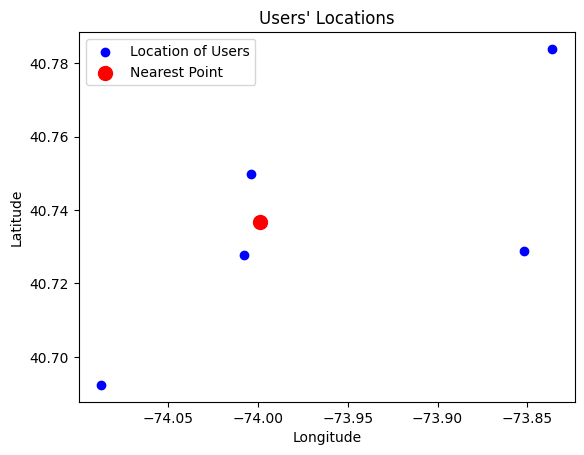

In [ ]:
import matplotlib.pyplot as plt

# All points except the last
plt.scatter(coordinates['Longitude'][:-1], coordinates['Latitude'][:-1], color='blue', label='Location of Users')

# Highlight the nearest point in red
plt.scatter(coordinates['Longitude'].iloc[-1], coordinates['Latitude'].iloc[-1], color='red', label='Nearest Point', s=100)

# Axis labels
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Scatter Plot Title
plt.title("Users' Locations")

plt.legend()

plt.show()


Suggestion to meet at particular venue/place

In [ ]:
# Function to find the Venue_ID with the shortest distance to a given reference point
# Input:
#   df – DataFrame containing Venue_IDs with their corresponding 'Latitude' and 'Longitude'
#   reference_point – Tuple (latitude, longitude) representing the reference location
# Output:
#   A Series containing the Venue_ID, Venue_Category_Name, Latitude, Longitude, and distance
#   of the venue closest to the given reference point
from geopy.distance import geodesic
def find_nearest_venue(df, reference_point):
    df_copy = df.copy()
    df_copy['distance'] = df_copy.apply(lambda row:geodesic(reference_point, (row['Latitude'], row['Longitude'])).kilometers, axis=1)
    nearest_checkin = df_copy.loc[df_copy['distance'].idxmin()]
    return nearest_checkin[['Venue_ID', 'Venue_Category_Name', 'Latitude', 'Longitude', 'distance']] 

In [ ]:
def common_nearest_venue(df):
    commonCentralPoint = centralPoint(df)
    nearestVenue = find_nearest_venue(df,commonCentralPoint)
    print("Suggested Meeting Location")
    print(nearestVenue)
    return nearestVenue

In [146]:
meeting_venue = common_nearest_venue(checkIn)

Current location
    ID   Latitude  Longitude
0   59  40.783910 -73.836108
1  911  40.692337 -74.087248
2  119  40.758457 -73.989140
3  420  40.749783 -74.004073
4  590  40.728787 -73.851986
Nearest Point to all users
[ 40.75661721 -73.98873859]
Suggested Meeting Location
Venue_ID               4ab52081f964a520a57220e3
Venue_Category_Name                       Hotel
Latitude                              40.756648
Longitude                            -73.988705
distance                               0.004436
Name: 60480, dtype: object


# Recommend a list of 10 unvisited locations

Approach: TF-IDF and Cosine Similarity (text-based):
Category similarity is determined by analyzing the textual information contained in the Unique_Venue_Category_Name and Category_Path fields, where TF-IDF is used to create numerical representations of the text and cosine similarity is applied to quantify the similarity between categories.


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [126]:
category = pd.read_excel("CategoryNameAndLabels.xlsx", sheet_name="Sheet1")
print(category.columns.tolist())

['User_ID', 'Venue_Category_ID', 'Venue_Category_Name', 'Unique_Venue_Category_Name', 'Main_Category', 'Category_Path']


In [127]:
#Create a new column where the different hierarchical levels of the category are concatenated
category['category_path'] = category['Category_Path'].str.replace(' > ', ' ') 
print(category)

     User_ID         Venue_Category_ID              Venue_Category_Name  \
0          3  4bf58dd8d48988d18f941735                       Art Museum   
1          4  4bf58dd8d48988d14f941735  Southern / Soul Food Restaurant   
2          9  4bf58dd8d48988d167941735                 Athletic & Sport   
3         15  4bf58dd8d48988d1dd931735                       Soup Place   
4         16  4bf58dd8d48988d12c941735              Government Building   
..       ...                       ...                              ...   
395     1057  4bf58dd8d48988d1ef931735                          Airport   
396     1059  4bf58dd8d48988d187941735                          Stadium   
397     1063  4d954b0ea243a5684a65b473                Convenience Store   
398     1070  4bf58dd8d48988d165941735                   Scenic Lookout   
399     1082  4f4531504b9074f6e4fb0102                    Train Station   

          Unique_Venue_Category_Name              Main_Category  \
0                         Art Mu

TF-IDF is applied to create vectors that capture the similarity between categories using the text in their labels.

In [ ]:
#Function to find the most similar categories based on text similarity with TF-IDF
def top_5_similar_categories_tfidf(category, categoryID):
    vectorizer = TfidfVectorizer() 
    # Create a TF-IDF matrix from the category paths
    tfidf_matrix = vectorizer.fit_transform(category['category_path'])
    # Compute cosine similarity between all category vectors
    cosine_sim = cosine_similarity(tfidf_matrix)
    # Store cosine similarity scores in a DataFrame indexed by Venue_Category_ID
    sim_df = pd.DataFrame(cosine_sim, index=category['Venue_Category_ID'], columns=category['Venue_Category_ID'])
    # Select the five most similar categories for the given categoryID (excluding itself)
    similar_categories = sim_df[categoryID].sort_values(ascending=False)[1:6]  # get the most 5 similar categories
    #Convert similarity scores to a DataFrame and add category details
    similar_categories = similar_categories.to_frame(name='distance_toCategory')
    similar_categories = pd.merge(similar_categories,category, on='Venue_Category_ID', how='left')
    return similar_categories
    

In [ ]:
similar_categories = top_5_similar_categories_tfidf(category, '4bf58dd8d48988d116951735')

In [13]:
print(similar_categories)

          Venue_Category_ID  distance_toCategory  User_ID Venue_Category_Name  \
0  4bf58dd8d48988d1ff941735             0.612809      225  Miscellaneous Shop   
1  4f04b08c2fb6e1c99f3db0bd             0.612809      190  Miscellaneous Shop   
2  4bf58dd8d48988d115951735             0.391051      100           Bike Shop   
3  4bf58dd8d48988d124951735             0.375535       53     Automotive Shop   
4  4bf58dd8d48988d128951735             0.375535      986           Gift Shop   

  Unique_Venue_Category_Name Main_Category             Category_Path  \
0                     Shop B        Retail           Retail > Shop B   
1                     Shop A        Retail           Retail > Shop A   
2                  Bike Shop        Retail        Retail > Bike Shop   
3            Automotive Shop        Retail  Retail > Automotive Shop   
4                  Gift Shop        Retail        Retail > Gift Shop   

            category_path  
0           Retail Shop B  
1           Retail Shop 

Question 1: Giving a UserID and a categoryID recommend unvisited location with similar categories to the one inserted
1. create data frame with unvisited locations

In [ ]:
def unvisted_locations(df, UserID):
    # Filter the data for the specified user
    user_df = df[df['User_ID'] == UserID]
    
    # Retrieve the Venue_IDs visited by the user
    visited_venues = set(user_df['Venue_ID'])
    
    # Retrieve all unique Venue_IDs in the dataset
    all_venues = set(df['Venue_ID'])
    
    # Determine the Venue_IDs that have not been visited by the user
    unvisited_venues = all_venues - visited_venues
    
    return pd.Series(list(unvisited_venues), name='Venue_ID')

Unvisited Venues of a User ID 300

In [132]:
unvisted_venues= unvisted_locations(checkIn,300)
print(unvisted_venues)
print(type(unvisted_venues))

0        4cd98dea1647a0939d9be74c
1        4d1d4d76bdd7a093e617d3ce
2        4cbb313a4495721e9b4b547a
3        4fe5d852e4b0b901afd5864a
4        4b5f2903f964a520f5a929e3
                   ...           
38254    4e38a2cfbd415d9f63d71183
38255    4ee207b3490152e4bcc0bd00
38256    4c5dec7b9b28d13a98185b70
38257    4f1c7230e4b07befff045db0
38258    45e82773f964a52066431fe3
Name: Venue_ID, Length: 38259, dtype: object
<class 'pandas.core.series.Series'>


Function to provide the top 10 venue recommendations for a specific user

In [ ]:
def recommend_venue(checkIn_df, category_df):
    userID = int(input("UserID (between 1 and 1083): "))
    categoryID = input("CategoryID: ")

    # 1. Find 5 most similar categories
    simCategories = top_5_similar_categories_tfidf(category_df, categoryID)  
 
    # 2. Find unvisited venues for the user
    unvisited_Venues = unvisted_locations(checkIn_df, userID)  
    # [NO CHANGE] Returned: Series, column='Venue_ID'

    # 3. Find similar users. Dynamically calculate total users.
    total_users = checkIn_df['User_ID'].nunique()
    simUsers = mostSimUsers(checkIn_df, userID, total_users - 1)  
    
    # 4. Filter check-ins for unvisited venues
    filtered_df = checkIn_df[checkIn_df['Venue_ID'].isin(unvisited_Venues)]

    # 5. Merge with similar users info
    filtered_df = pd.merge(filtered_df, simUsers, left_on='User_ID', right_on='ID', how='left')

    # 6. Keep only venues in similar categories
    filtered_df = filtered_df[filtered_df['Venue_Category_ID'].isin(simCategories['Venue_Category_ID'])]

    # 7. Sort by user ranking and take top 10
    results = filtered_df.sort_values(by=['user_ranking'], ascending=True).head(10)

    print(f"Top 10 Recommended Locations for User {userID}:")
    return results[['Venue_ID', 'Venue_Category_ID', 'Unique_Venue_Category_Name']]


# Results

Question/Use case 2: Find the list of top 10 most similar users (i.e. their interests match) in the entire data set for any userID as input.

In [86]:
find10mostSimUsers(checkIn)


Top 10 similar Users for User 844:
    ID  Distance (KNN)  user_ranking
0  571        0.950134             1
1  892        0.970882             2
2  301        0.972783             3
3  644        0.974998             4
4  600        0.977700             5
5  960        0.978240             6
6  398        0.980069             7
7  266        0.984355             8
8  922        0.984578             9
9  979        0.984610            10


,ID,Distance (KNN),user_ranking
0,571,0.950134,1
1,892,0.970882,2
2,301,0.972783,3
3,644,0.974998,4
4,600,0.977700,5
5,960,0.978240,6
6,398,0.980069,7
7,266,0.984355,8
8,922,0.984578,9
9,979,0.984610,10


Question/User case 3: For a given set of 5 userIDs and their randomly selected locations from data, recommend a place where these 5 people can meet.

In [148]:
meeting_venue = common_nearest_venue(checkIn)

Current location
    ID   Latitude  Longitude
0   59  40.783910 -73.836108
1  911  40.692337 -74.087248
2  119  40.758457 -73.989140
3  420  40.749783 -74.004073
4  590  40.728787 -73.851986
Nearest Point to all users
[ 40.75661721 -73.98873859]
Suggested Meeting Location
Venue_ID               4ab52081f964a520a57220e3
Venue_Category_Name                       Hotel
Latitude                              40.756648
Longitude                            -73.988705
distance                               0.004436
Name: 60480, dtype: object


Question/User case 1: Recommend a list of 10 unvisited locations for any userID and CatagoryID


In [136]:
result_list = recommend_venue(checkIn, category)
print(result_list)

Top 10 Recommended Locations for User 12:
                        Venue_ID         Venue_Category_ID  \
138997  4c66ed9b19f3c9b6ed5ca1ff  4bf58dd8d48988d1e7941735   
185297  4e64846b18a8ce02fdc01c5e  4d4b7105d754a06377d81259   
153659  4cf4ba5694feb1f78e7629ba  4bf58dd8d48988d1e7941735   
139678  4c6c528423c1a1cd563f19cf  4bf58dd8d48988d1e7941735   
126407  4c0c04c5009a0f473200ecbf  4bf58dd8d48988d1e7941735   
60741   4abb7c34f964a520d28320e3  4bf58dd8d48988d1e7941735   
135529  4c4c27ce959220a1fa749710  4bf58dd8d48988d1e7941735   
190067  4e88e7af9a52a2df9baf8fbd  4d4b7105d754a06377d81259   
122326  4bf6f66a5ec320a14b1c86d3  4bf58dd8d48988d1e7941735   
165574  4d9e38b8009b224bda61e6d1  4bf58dd8d48988d1e7941735   

          Venue_Category_Name  
138997             Playground  
185297  Outdoors & Recreation  
153659             Playground  
139678             Playground  
126407             Playground  
60741              Playground  
135529             Playground  
190067  Outdoors & 